# Northeast Pacific Daily Ocean Temperature (GLORYS12): Identifying Marine Extremes at Depth with marEx

This notebook turns 30 years (1993-2022) of daily potential temperature into a boolean record of marine heatwaves at
every depth. The input is the 1/12° GLORYS12 reanalysis over the northeast Pacific (30°N-60°N, 170°W-120°W) on 36 levels
from the surface to 1150 m, written by [`00_download_glorys12.ipynb`](00_download_glorys12.ipynb). The anomaly removes a
linear trend and a fixed 1993-2022 day-of-year climatology (`detrend_fixed_baseline`), and the threshold is the
day-of-year 95th percentile (`seasonal_percentile`, Hobday et al., 2016). Only 2013-2016 is written, the years of the
Blob, which [`02_track_extremes_4d.ipynb`](02_track_extremes_4d.ipynb) tracks in time and space and
[`03_visualise_events.ipynb`](03_visualise_events.ipynb) visualises. The events of those years lie inside the baseline,
so the climatology and the threshold are estimated from a record that includes them.

Detection needs nothing new to run at depth. `preprocess_data` finds the extra `depth` dimension, treats each level
independently, and adds `depth` to every spatial output. The rules are under
[Extra Dimensions](https://marex.readthedocs.io/en/latest/guide/dimensions_and_time.html#extra-dimensions).

Compute: 256 SLURM workers × 7.8 GB, started by this notebook (8 nodes). The input is 340 GB in memory, more than one
node holds.

## Setup

In [1]:
from getpass import getuser
from pathlib import Path

import cartopy.crs as ccrs
import dask
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import marEx
import marEx.helper as hpc

2026-11-02 15:17:42 - marEx - INFO - [PID:356789] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()
input_dir = scratch_dir / "marEx_data" / "input" / "glorys12_nepacific"  # written by 00_download_glorys12.ipynb
out_dir = scratch_dir / "marEx" / "examples" / "4d"

baseline = (1993, 2022)  # years of the climatology, the trend and the percentile
period = slice("2013-01-01", "2016-12-31")  # the years written to disk
map_depths = (0, 50, 100, 200, 400, 600, 800, 1000)  # m, the levels drawn in section 3
points = {
    "Station Papa": (50.0, -145.0),
    "Northeast Pacific": (44.0, -135.0),
    "California Current": (34.0, -125.0),
    "Subtropical gyre": (32.0, -155.0),
}  # (lat, lon), all ocean down to 1150 m

# 256 single-threaded workers as short SLURM jobs, 32 per 256 GB node (7.8 GB each)
n_workers, workers_per_node, runtime = 256, 32, 49  # workers, per 256 GB node, minutes per worker job

In [3]:
out_dir.mkdir(parents=True, exist_ok=True)

# graphs of a few hundred MB are expected at this scale
dask.config.set({"distributed.admin.large-graph-warning-threshold": "1GB"})

# Each group of 32 workers is one SLURM job. The job walls cover the whole run, because dask's P2P rechunk needs every
# worker until the shuffle completes.
client = hpc.start_distributed_cluster(
    n_workers=n_workers,
    workers_per_node=workers_per_node,
    runtime=runtime,
    node_memory=256,
    scratch_dir=scratch_dir / "marEx" / "dask",
)
client.wait_for_workers(n_workers, timeout=1800)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-11-02 15:17:55 - marEx.helper.cluster - INFO - [PID:356789] - Starting distributed SLURM cluster - 256 workers on 8 nodes


2026-11-02 15:17:55 - marEx.helper.cluster - INFO - [PID:356789] - Configuration: 32 workers/node x 1 threads, 256GB memory/node, 49 min runtime


2026-11-02 15:17:55 - marEx.helper.dask_config - INFO - [PID:356789] - Configuring Dask for HPC environment


2026-11-02 15:17:55 - marEx.helper.dask_config - INFO - [PID:356789] - Using scratch directory: /scratch/<u>/<user>/marEx/dask


2026-11-02 15:17:55 - marEx.helper.dask_config - INFO - [PID:356789] - Dask temporary directory: /scratch/<u>/<user>/marEx/dask/tmpg1c3ru47


2026-11-02 15:17:55 - marEx.helper.dask_config - INFO - [PID:356789] - Dask configuration completed


... (3 outputs left out)

2026-11-02 15:17:57 - marEx.helper.cluster - INFO - [PID:356789] - Memory limit per worker: 7.81 GB


2026-11-02 15:17:57 - marEx.helper.cluster - INFO - [PID:356789] - Scaling cluster to 256 workers


Hostname: l30666
Forward Port: l30666:8889
Dashboard Link: localhost:8889/status
2026-11-02 15:17:58 - marEx.helper.cluster - INFO - [PID:356789] - Distributed cluster started successfully


2026-11-02 15:24:39 - marEx.helper.resources - INFO - [PID:356789] - Cluster: 256 workers, 256 threads, memory_limit per worker [7.8] GB (2001 GB total)


## 1. The Input and Its Warming

One store per year contains `thetao` on `(time, depth, lat, lon)`, read with the store's on-disk chunking of 10 days and
everything else whole. Cells that are NaN on any day are masked on every day through `valid`, so the finite-data check
and the output mask agree. The depth coordinate records its units and sign, which the tracker reads later.

The anomaly removes a trend because the area-mean warming over the 30 years differs between levels, so a
fixed climatology alone would count steadily more of the record as extreme at some depths than at others.

In [5]:
years = range(baseline[0], baseline[1] + 1)
thetao = xr.open_mfdataset(
    [input_dir / f"thetao_{year}.zarr" for year in years],
    engine="zarr",
    chunks={},
    combine="nested",
    concat_dim="time",
    data_vars="minimal",
    coords="minimal",
    compat="override",
).thetao.chunk({"time": 10, "depth": -1, "lat": -1, "lon": -1})

valid = xr.open_zarr(input_dir / "glorys12_valid.zarr").valid.astype(bool).assign_coords(depth=thetao.depth)
static = xr.open_zarr(input_dir / "glorys12_static.zarr").assign_coords(depth=thetao.depth)

thetao = thetao.where(valid)
thetao = thetao.assign_coords(depth=thetao.depth.assign_attrs(units="m", positive="down", long_name="level centre depth"))
thetao

<env>/lib/python3.10/site-packages/dask/array/core.py:4997: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(


<xarray.DataArray 'thetao' (time: 10957, depth: 36, lat: 361, lon: 601)> Size: 342GB
dask.array<where, shape=(10957, 36, 361, 601), dtype=float32, chunksize=(10, 9, 181, 301), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 1kB 30.0 30.08 30.17 30.25 ... 59.75 59.83 59.92 60.0
  * lon      (lon) float32 2kB -170.0 -169.9 -169.8 ... -120.2 -120.1 -120.0
  * time     (time) datetime64[ns] 88kB 1993-01-01 1993-01-02 ... 2022-12-31
  * depth    (depth) float32 144B 0.494 1.541 2.646 ... 763.3 902.3 1.062e+03
Attributes:
    long_name:  sea water potential temperature
    units:      degC

Input: annual level means: 2.4 min, peak worker memory 495.3 GB of 2001 GB (largest worker 2.9 of 7.8 GB), client 1.6 GB, spilled 0.0 GB, restarts 0


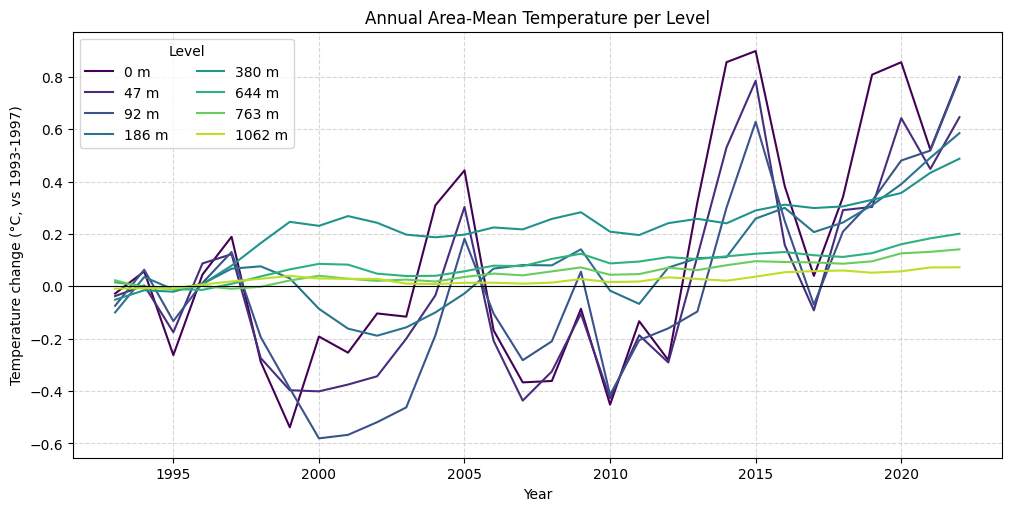

In [6]:
with monitor.stage("Input: annual level means"):
    weights = np.cos(np.deg2rad(thetao.lat))
    level_means = thetao.weighted(weights).mean(dim=["lat", "lon"]).resample(time="YE").mean().compute()

drift = level_means - level_means.isel(time=slice(0, 5)).mean("time")

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
levels = np.abs(drift.depth.values[:, None] - np.array(map_depths)).argmin(axis=0)
colours = plt.cm.viridis(np.linspace(0, 0.9, len(levels)))
for colour, level in zip(colours, levels):
    profile = drift.isel(depth=level)
    ax.plot(profile.time.dt.year, profile, color=colour, label=f"{float(profile.depth):.0f} m")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Year")
ax.set_ylabel(f"Temperature change (°C, vs {baseline[0]}-{baseline[0] + 4})")
ax.set_title("Annual Area-Mean Temperature per Level")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(ncol=2, title="Level")
plt.show()

## 2. Fixed Baseline & Hobday Threshold at Depth

The arguments are those of the surface examples, with one addition. `precision` is the bin width of the approximate
percentile, and all levels share one set of bins. The anomaly standard deviation falls by more than an order of
magnitude between the surface and 1000 m, so the width is set from the quietest level rather than left at its default
of 3000 bins over the data's range. marEx logs the extra dimension it found, and every output with a spatial dimension
gains `depth`: `mask` is `(depth, lat, lon)`, because the sea floor rises above the deeper levels, and `thresholds` is
`(depth, lat, lon, dayofyear)`.

The output keeps 2013-2016, so the 340 GB input reduces to 46 GB of anomalies. Next to the extremes go the layer
interfaces `depth_bnds` and the cell areas `cell_area`, which the tracker uses for physical volumes.

In [7]:
with monitor.stage("Detect: fixed baseline + Hobday"):
    extremes_ds = marEx.preprocess_data(
        thetao,
        method_anomaly="detrend_fixed_baseline",  # linear trend removed, then a fixed day-of-year climatology
        method_extreme="seasonal_percentile",  # day-of-year threshold (Hobday et al., 2016)
        threshold_percentile=95,
        detrend_orders=[1],
        reference_period=baseline,
        smooth_days=31,  # smoothing applied to the climatology (days)
        window_days=11,  # samples from an 11-day window around each day of year enter its percentile
        precision=0.002,  # histogram bin width (°C), set from the quietest level
        dimensions={"time": "time", "x": "lon", "y": "lat"},  # `depth` is found automatically
        dask_chunks={"time": 25},  # chunking of the output
    )
    # The slice can start part way through a chunk, and Zarr needs a uniform first chunk
    extremes_ds = extremes_ds.sel(time=period).chunk({"time": 25})
    extremes_ds = extremes_ds.assign(cell_area=static.cell_area.astype("f8"), depth_bnds=static.depth_bnds.astype("f8"))
    extremes_ds.to_zarr(out_dir / "extremes_glorys12_4d.zarr", mode="w")
extremes_ds

2026-11-02 15:27:22 - marEx.pipeline - INFO - [PID:356789] - Starting data preprocessing - Method: detrend_fixed_baseline -> seasonal_percentile


2026-11-02 15:27:22 - marEx.pipeline - INFO - [PID:356789] - Parameters: percentile=95%, method_percentile=approximate


2026-11-02 15:27:22 - marEx.anomaly.api - INFO - [PID:356789] - Computing anomalies - method: detrend_fixed_baseline


2026-11-02 15:27:22 - marEx.anomaly.api - INFO - [PID:356789] - Extra (non-horizontal) dimensions detected and carried through: ['depth']


2026-11-02 15:28:23 - marEx.anomaly.api - INFO - [PID:356789] - Starting Anomaly computation using detrend_fixed_baseline method


2026-11-02 15:28:40 - marEx.anomaly.api - INFO - [PID:356789] - Completed Anomaly computation using detrend_fixed_baseline method in 16.59s


... (5 outputs left out)

2026-11-02 15:47:52 - marEx.core.finalise - INFO - [PID:356789] - Completed Dataset persistence and optimisation in 0.88s


2026-11-02 15:54:07 - marEx.extremes.api - INFO - [PID:356789] - Extreme identification completed - <xarray.DataArray 'extreme_events' ()> Size: 8B
array(3527403550) extreme events identified


Detect: fixed baseline + Hobday: 26.9 min, peak worker memory 1228.1 GB of 2001 GB (largest worker 5.8 of 7.8 GB), client 7.7 GB, spilled 724.0 GB, restarts 0


<xarray.Dataset> Size: 69GB
Dimensions:         (lat: 361, lon: 601, time: 1461, depth: 36, dayofyear: 366,
                     bnds: 2)
Coordinates:
  * lat             (lat) float32 1kB 30.0 30.08 30.17 ... 59.83 59.92 60.0
  * lon             (lon) float32 2kB -170.0 -169.9 -169.8 ... -120.1 -120.0
  * time            (time) datetime64[ns] 12kB 2013-01-01 ... 2016-12-31
  * depth           (depth) float32 144B 0.494 1.541 2.646 ... 902.3 1.062e+03
  * dayofyear       (dayofyear) uint16 732B 1 2 3 4 5 6 ... 362 363 364 365 366
Dimensions without coordinates: bnds
Data variables:
    dat_anomaly     (time, depth, lat, lon) float32 46GB dask.array<chunksize=(25, 9, 361, 601), meta=np.ndarray>
    mask            (depth, lat, lon) bool 8MB dask.array<chunksize=(9, 361, 601), meta=np.ndarray>
    extreme_events  (time, depth, lat, lon) bool 11GB dask.array<chunksize=(25, 9, 361, 601), meta=np.ndarray>
    thresholds      (depth, lat, lon, dayofyear) float32 11GB dask.array<chunksize=(9, 361, 601, 25), meta=np.ndarray>
    cell_area       (lat, lon) float64 2MB dask.array<chunksize=(181, 301), meta=np.ndarray>
    depth_bnds      (depth, bnds) float64 576B dask.array<chunksize=(36, 2), meta=np.ndarray>
Attributes: (12/14)
    method_anomaly:        detrend_fixed_baseline
    preprocessing_steps:   ['Removed polynomial trend orders=[1]', 'Daily cli...
    detrend_orders:        [1]
    force_zero_mean:       1
    smooth_days:           31
    reference_period:      [1993, 2022]
    ...                    ...
    tail:                  upper
    window_days:           11
    window_spatial:        5
    method_percentile:     approximate
    precision:             0.002
    max_anomaly:           8.473458290100098

## 3. Maps per Level

`plotX` draws one map per panel, so a field with `depth` is plotted one level per panel with `col="depth"`. The
threshold is an anomaly, so it shows how far above its climatology the water at that depth must be to count as extreme.

A 95th percentile flags 5% of days over the baseline. Over 2013-2016 the area-mean frequency is 9.8% at the surface and
peaks at 11.8% at 66 m, then falls to 3.8% at 454 m, which puts these years well above the baseline rate in the upper
ocean and below it at mid-depth.

Analysis: maps per level: 0.3 min, peak worker memory 429.1 GB of 2001 GB (largest worker 3.5 of 7.8 GB), client 7.8 GB, spilled 0.0 GB, restarts 0
2026-11-02 15:54:38 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 1.32s


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.05s


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


... (6 outputs left out)

2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.05s


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:39 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


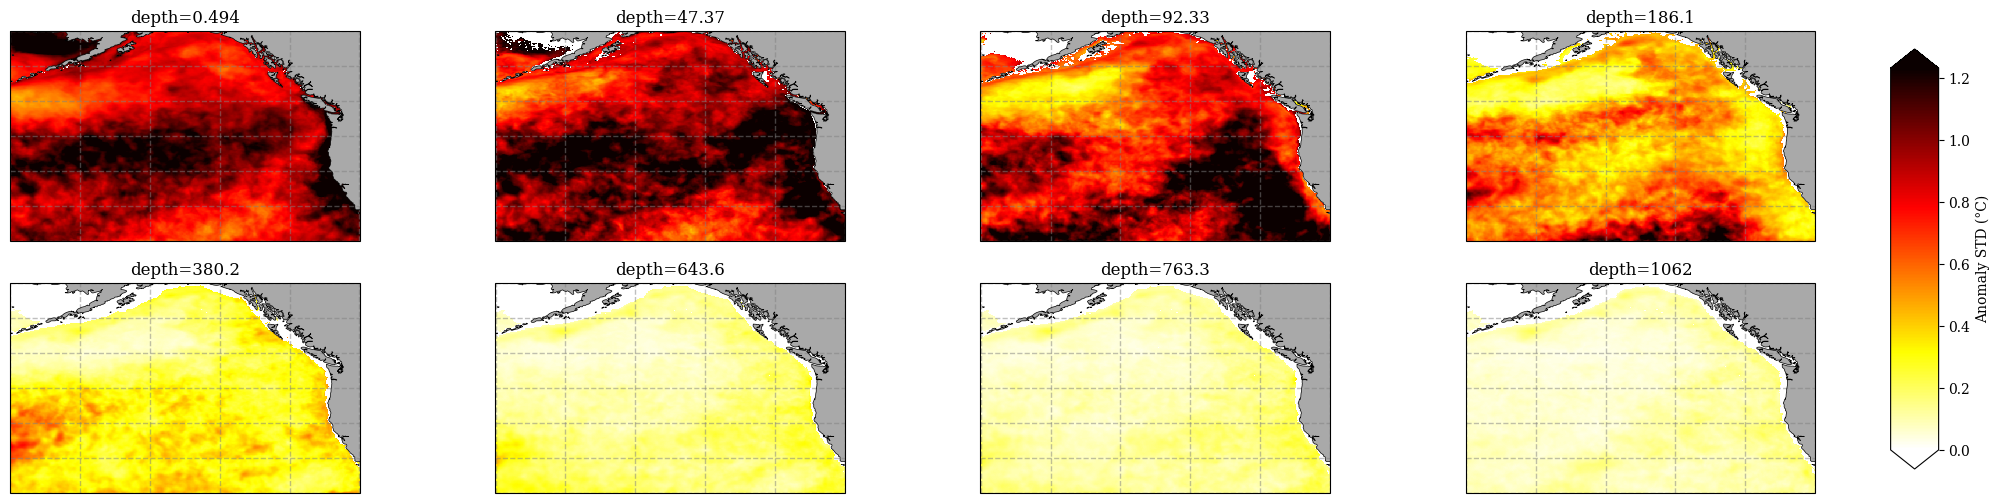

2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.05s


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.05s


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


... (6 outputs left out)

2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:42 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.05s


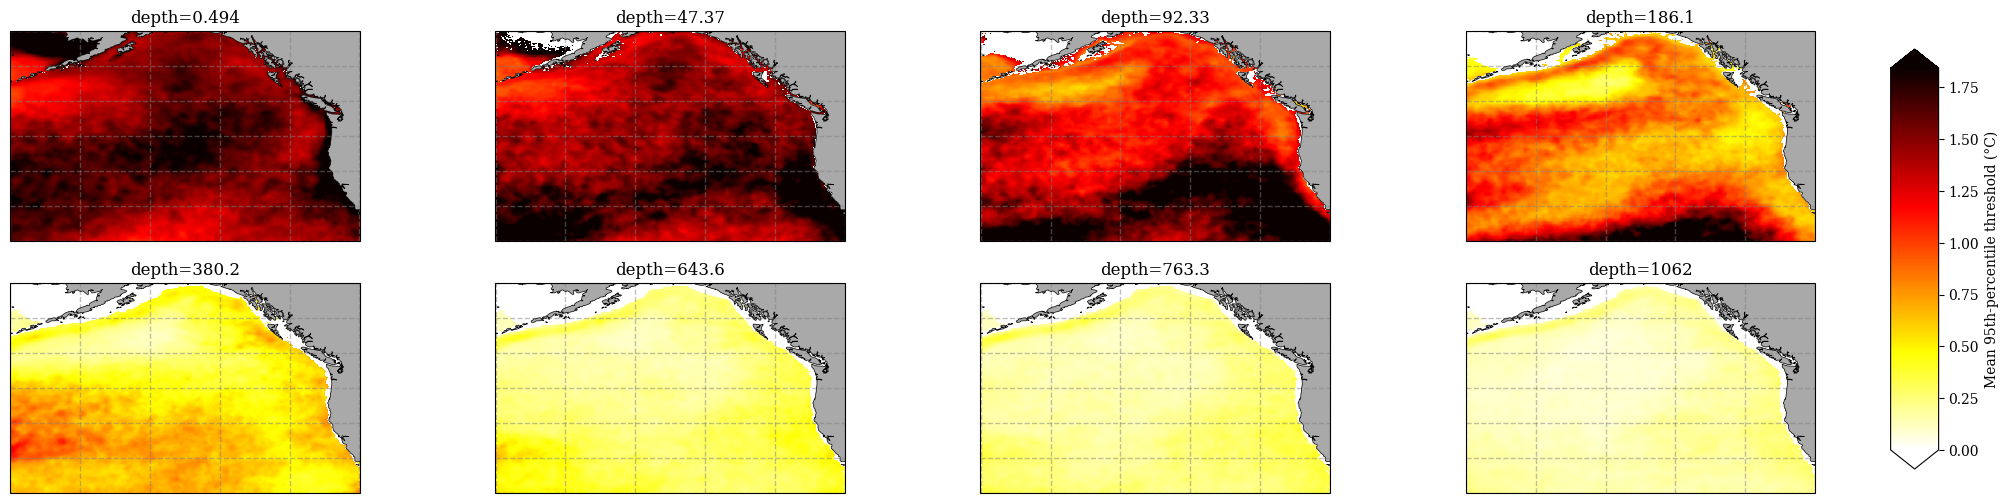

In [8]:
extremes_ds = xr.open_zarr(out_dir / "extremes_glorys12_4d.zarr", chunks={})
plot_chunks = {"time": 75, "depth": 1, "lat": -1, "lon": -1}
anomaly = extremes_ds.dat_anomaly.chunk(plot_chunks)
events = extremes_ds.extreme_events.chunk(plot_chunks)

with monitor.stage("Analysis: maps per level"):
    level_maps = xr.Dataset(
        {
            "frequency": events.mean(dim="time"),
            "anomaly_std": anomaly.std(dim="time"),
            "threshold": extremes_ds.thresholds.mean(dim="dayofyear"),
        }
    ).compute()

map_levels = np.unique(np.abs(extremes_ds.depth.values[:, None] - np.array(map_depths)).argmin(axis=0))
map_kwargs = {"grid_labels": False, "show_colorbar": True, "projection": ccrs.PlateCarree()}
for name, units, cmap in [
    ("anomaly_std", "Anomaly STD (°C)", "hot_r"),
    ("threshold", "Mean 95th-percentile threshold (°C)", "hot_r"),
]:
    config = marEx.PlotConfig(var_units=units, cmap=cmap, cperc=[0, 96], **map_kwargs)
    fig, axes = level_maps[name].isel(depth=map_levels).plotX.multi_plot(config, col="depth", col_wrap=4)
    plt.show()

2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.05s


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


... (6 outputs left out)

2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Starting Gridded plot rendering


2026-11-02 15:54:44 - marEx.plotX.gridded - INFO - [PID:356789] - Completed Gridded plot rendering in 0.04s


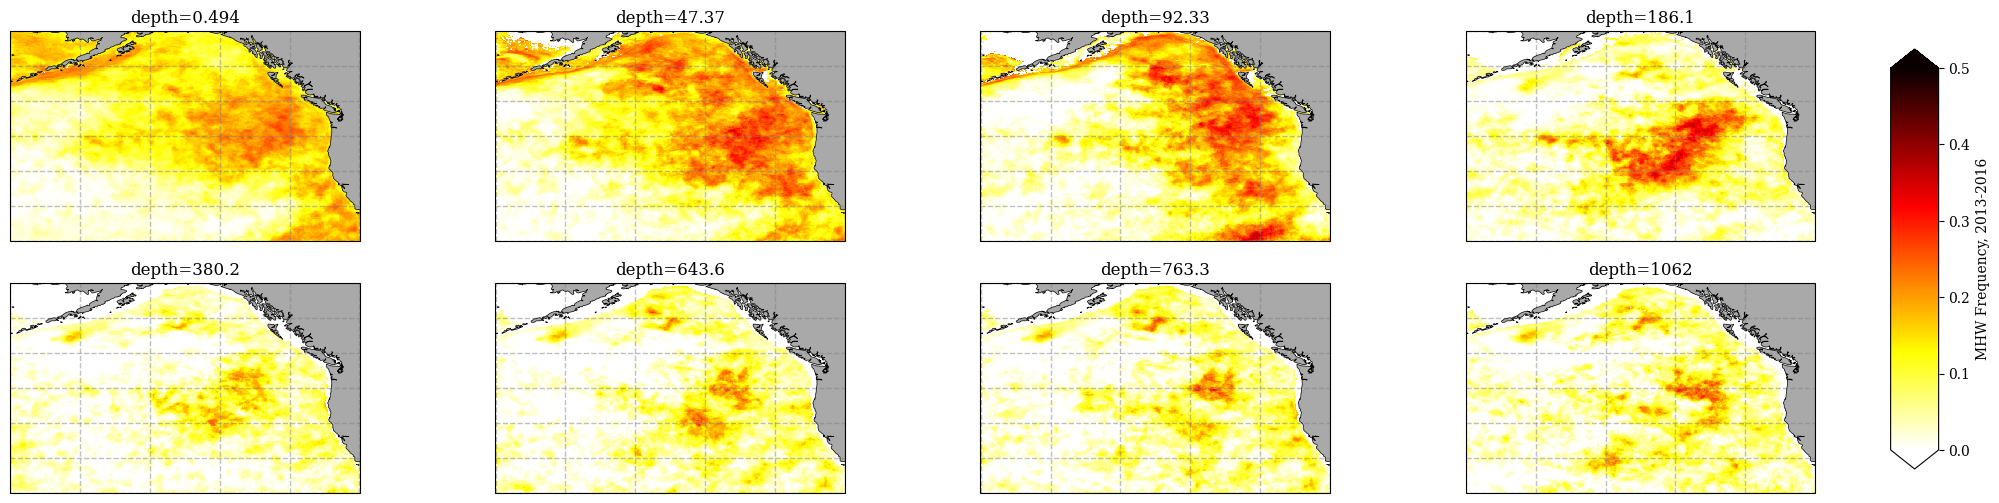

In [9]:
config = marEx.PlotConfig(var_units="MHW Frequency, 2013-2016", cmap="hot_r", clim=[0, 0.5], **map_kwargs)
fig, axes = level_maps.frequency.isel(depth=map_levels).plotX.multi_plot(config, col="depth", col_wrap=4)
plt.show()

## 4. Depth-Time Sections

The anomaly at four points, level against time, with the days flagged as extreme outlined. The levels are unevenly
spaced, so each is drawn as one row of equal height.

Averaged over levels and days, the upper 78 m at Station Papa is extreme 55% of the time in 2014 and 6% in 2015. At
44°N, 135°W the peak is a year later, 66% in 2015, and there the levels from 92 m down reach 44% in the same year. The
California Current follows at 40% in 2015. In the subtropical gyre the upper 78 m reaches at most 1.1%, in 2013.

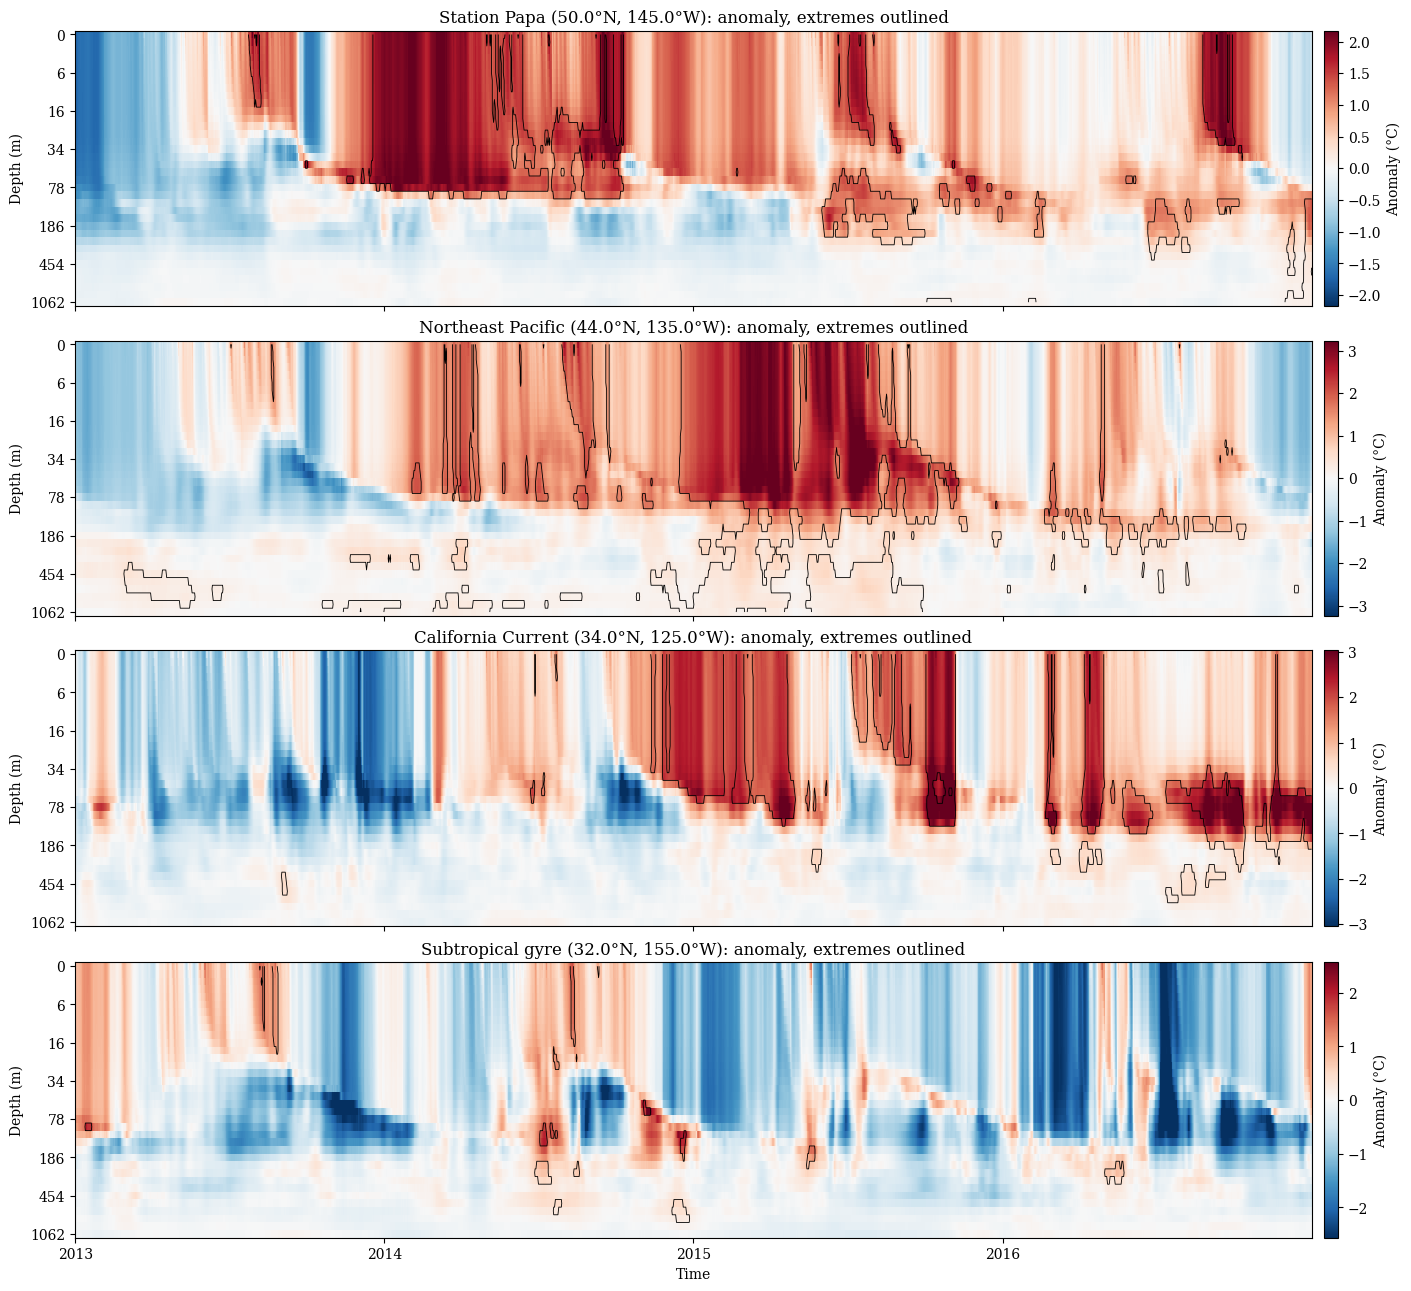

In [10]:
fig, axes = plt.subplots(len(points), 1, figsize=(14, 3.2 * len(points)), sharex=True, layout="constrained")
for ax, (name, (lat_pt, lon_pt)) in zip(axes, points.items()):
    at_point = {"lat": lat_pt, "lon": lon_pt}
    anomaly_pt = extremes_ds.dat_anomaly.sel(**at_point, method="nearest").compute()
    events_pt = extremes_ds.extreme_events.sel(**at_point, method="nearest").compute()
    limit = float(np.nanpercentile(np.abs(anomaly_pt), 99))
    rows = np.arange(anomaly_pt.sizes["depth"])
    mesh = ax.pcolormesh(anomaly_pt.time, rows, anomaly_pt.T, cmap="RdBu_r", vmin=-limit, vmax=limit, shading="nearest")
    ax.contour(events_pt.time, rows, events_pt.T.astype(int), levels=[0.5], colors="black", linewidths=0.6)
    ax.set_yticks(rows[::5], [f"{depth:.0f}" for depth in anomaly_pt.depth.values[::5]])
    ax.invert_yaxis()
    ax.set_ylabel("Depth (m)")
    ax.set_title(f"{name} ({lat_pt}°N, {abs(lon_pt)}°W): anomaly, extremes outlined")
    fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", pad=0.01)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].set_xlabel("Time")
plt.show()

## 5. Vertical Structure

The left panel shows how variability and the threshold change with depth, as area-weighted means over the ocean at each
level. The right panel counts, over all cells at a level, how often an extreme also has a surface extreme in the same
column on the same day. The fraction falls to 0.38 at 78 m and lies between 0.16 and 0.20 from 186 m down. If surface and
depth extremes were independent it would be 0.10, or 0.12 to 0.13 allowing for columns that are extreme more often. A
surface threshold misses most of these extremes on the day, although at 92 m the surface
anomaly is positive above 94% of them, compared with 58% when the surface is taken two years away.

Analysis: vertical profiles: 0.1 min, peak worker memory 341.2 GB of 2001 GB (largest worker 2.8 of 7.8 GB), client 8.4 GB, spilled 0.0 GB, restarts 0


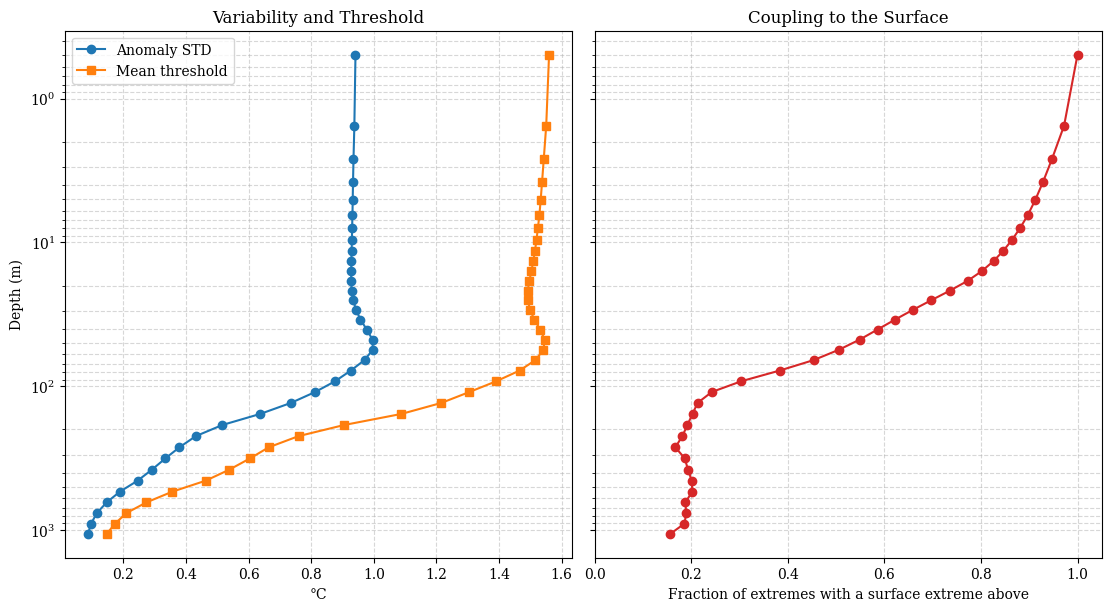

,frequency,anomaly_std,threshold,with_surface
depth,,,,
0.494025,0.098,0.941,1.560,1.000
6.440614,0.102,0.932,1.529,0.897
15.810070,0.106,0.928,1.503,0.802
34.434151,0.109,0.957,1.513,0.622
77.853851,0.111,0.926,1.465,0.383
186.125595,0.068,0.516,0.905,0.192
453.937714,0.038,0.246,0.463,0.201
1062.439941,0.052,0.087,0.147,0.157


In [11]:
with monitor.stage("Analysis: vertical profiles"):
    weights = np.cos(np.deg2rad(extremes_ds.lat))

    def area_mean(field):
        return field.where(extremes_ds.mask).weighted(weights).mean(dim=["lat", "lon"])

    surface_events = events.isel(depth=0, drop=True)
    joint = (events & surface_events).sum(dim=["time", "lat", "lon"])
    profiles = xr.Dataset(
        {
            "frequency": area_mean(level_maps.frequency),
            "anomaly_std": area_mean(level_maps.anomaly_std),
            "threshold": area_mean(level_maps.threshold),
            "with_surface": joint / events.sum(dim=["time", "lat", "lon"]),
        }
    ).compute()

fig, (ax_var, ax_cond) = plt.subplots(1, 2, figsize=(11, 6), sharey=True, layout="constrained")
ax_var.plot(profiles.anomaly_std, profiles.depth, marker="o", label="Anomaly STD")
ax_var.plot(profiles.threshold, profiles.depth, marker="s", label="Mean threshold")
ax_var.set_xlabel("°C")
ax_var.set_ylabel("Depth (m)")
ax_var.set_title("Variability and Threshold")
ax_var.legend()

ax_cond.plot(profiles.with_surface, profiles.depth, marker="o", color="tab:red")
ax_cond.set_xlim(0, 1.05)
ax_cond.set_xlabel("Fraction of extremes with a surface extreme above")
ax_cond.set_title("Coupling to the Surface")
for ax in (ax_var, ax_cond):
    ax.set_yscale("log")
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax_var.invert_yaxis()
plt.show()

profiles.to_dataframe()[["frequency", "anomaly_std", "threshold", "with_surface"]].iloc[::5].round(3)

## Wall Time and Memory

Peak memory summed over workers, the largest single worker, and the client (this kernel), per stage. Detect is 26.9 of
the 29.7 minutes. No worker restarted and the largest peaked at 5.8 of 7.8 GB, but detect spilled 724 GB to disk, so
this cluster fits the run with spilling on rather than in memory.

In [12]:
monitor.summary()

,wall (min),peak worker memory (GB),peak per worker (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,,
Input: annual level means,2.41,495.32,2.91,1.55,0.00,0
Detect: fixed baseline + Hobday,26.94,1228.10,5.83,7.74,724.02,0
Analysis: maps per level,0.31,429.12,3.53,7.78,0.00,0
Analysis: vertical profiles,0.06,341.21,2.78,8.37,0.00,0
total,29.72,1228.10,5.83,8.37,724.02,0


In [13]:
client.close()